# OULAD: what the ontology adds

This notebook explains the Session 3 OWL extension of the AAA project. It reads the actual
HermiT results and CSV reconciliation checks. It does not rerun the reasoner or change the databases.
Use the existing **M2ENV** Python kernel when rerunning cells.

**Facts** say which student enrolled and which score was recorded. **Definitions** explain
what classes such as `SuccessfulEnrollment` mean. **Inference** identifies individuals
that satisfy those definitions without explicitly asserting their new type.

Run the README's Session 3 commands before this notebook if outputs are missing or stale.

In [1]:
from pathlib import Path
import hashlib, json, sys
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
from rdflib import Graph, Namespace, RDF, RDFS, OWL, URIRef

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/graph/prepare_ontology.py').exists())
OUT = ROOT / 'outputs/ontology'
EDU = Namespace('https://example.org/oulad/schema#')
full = json.loads((OUT / 'reasoned-full.json').read_text(encoding='utf-8'))
verification = json.loads((OUT / 'verification.json').read_text(encoding='utf-8'))
preparation = json.loads((OUT / 'preparation.json').read_text(encoding='utf-8'))
for report in [full, verification]:
    for name, digest in report['source_sha256'].items():
        assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest, 'Stale results: rerun README Session 3 commands.'
assert full['consistent'] and not full['unsatisfiable_classes']
assert verification['passed']
facts = Graph().parse(ROOT / 'data/processed/oulad.ttl')
inferred = Graph().parse(OUT / 'inferred-types-full.ttl')
sys.path.insert(0, str(ROOT / 'src/graph'))
from owl_reasoner import merged_graph
ontology = merged_graph(OUT / 'workspace/education.owl.ttl')
print('Python:', sys.executable)
print('Verified:', full['verified_at_utc'])
print('Asserted data triples:', len(facts), '| New named type assertions:', len(inferred))
print('Consistent: yes | Unsatisfiable named classes: none')
print('Checks passed:', len(verification['checks']))

Python: C:\Users\user\.conda\envs\M2ENV\python.exe
Verified: 2026-10-19T20:22:39.509132+00:00
Asserted data triples: 28470 | New named type assertions: 6119
Consistent: yes | Unsatisfiable named classes: none
Checks passed: 17


## 1. The existing relationships

Each arrow below is an object property, read from the ontology's domain and range.
For example, an **Enrollment hasStudent Student**. A Student is a person; an Enrollment
is that person's participation in one offering. Outcome belongs to the enrollment.

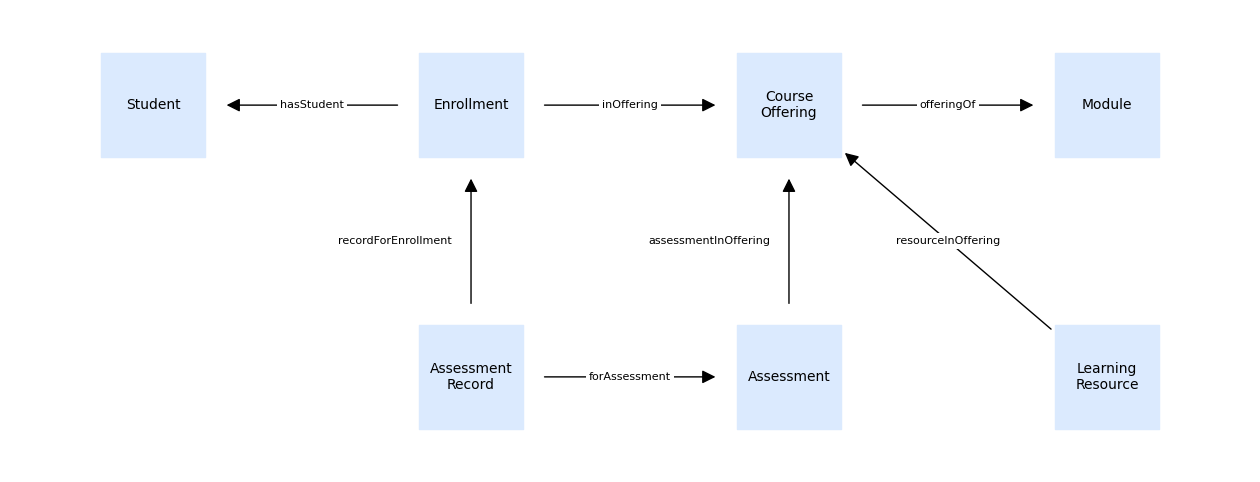

,from class,property,to class
0,Enrollment,hasStudent,Student
1,Enrollment,inOffering,CourseOffering
2,CourseOffering,offeringOf,Module
3,AssessmentRecord,recordForEnrollment,Enrollment
4,AssessmentRecord,forAssessment,Assessment
5,Assessment,assessmentInOffering,CourseOffering
6,LearningResource,resourceInOffering,CourseOffering


In [2]:
positions = {'Student': (0, 2), 'Enrollment': (2, 2), 'CourseOffering': (4, 2),
             'Module': (6, 2), 'AssessmentRecord': (2, 0), 'Assessment': (4, 0), 'LearningResource': (6, 0)}
properties = ['hasStudent', 'inOffering', 'offeringOf', 'recordForEnrollment',
              'forAssessment', 'assessmentInOffering', 'resourceInOffering']
relations = []
network = nx.DiGraph()
for name in properties:
    source = str(ontology.value(EDU[name], RDFS.domain)).split('#')[-1]
    target = str(ontology.value(EDU[name], RDFS.range)).split('#')[-1]
    relations.append({'from class': source, 'property': name, 'to class': target})
    network.add_edge(source, target, label=name)
fig, ax = plt.subplots(figsize=(16, 6))
nx.draw_networkx_nodes(network, positions, node_color='#dbeafe', node_size=5600, node_shape='s', ax=ax)
labels = {name: name.replace('AssessmentRecord', 'Assessment\nRecord').replace('CourseOffering', 'Course\nOffering').replace('LearningResource', 'Learning\nResource') for name in network.nodes}
nx.draw_networkx_labels(network, positions, labels=labels, font_size=10, ax=ax)
nx.draw_networkx_edges(network, positions, arrowsize=20, node_size=5600, node_shape='s', ax=ax)
for (source, target), label in nx.get_edge_attributes(network, 'label').items():
    x1, y1 = positions[source]; x2, y2 = positions[target]
    vertical = x1 == x2
    ax.text((x1+x2)/2 - (0.12 if vertical else 0), (y1+y2)/2, label,
            fontsize=8, ha='right' if vertical else 'center', va='center',
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 2})
ax.set_xlim(-0.9, 6.9); ax.set_ylim(-0.7, 2.7); ax.axis('off')
plt.show()
display(pd.DataFrame(relations))

## 2. Questions become definitions

These six classes answer specific project questions. `EquivalentTo` lets the reasoner
classify an individual from the facts. A one-way `SubClassOf` restriction alone does not
provide that reverse direction.

| Class | Meaning |
|---|---|
| SuccessfulEnrollment | Enrollment with outcome Pass or Distinction |
| WithdrawnEnrollment | Enrollment with outcome Withdrawn |
| LowScoreAssessmentRecord | AssessmentRecord with a known score strictly below 40 |
| BankedAssessmentRecord | AssessmentRecord with isBanked true |
| NonBankedAssessmentRecord | AssessmentRecord with isBanked false |
| EnrollmentWithLowScore | Enrollment with at least one low-score assessment record |

`hasAssessmentRecord` is the inverse of `recordForEnrollment`. It connects an enrollment
to its recorded results for the final definition. No rule says a low score implies final Fail.

In [3]:
display(pd.DataFrame(verification['inferred_counts']))

hierarchy = []
short = lambda iri: iri.split('#')[-1].rsplit('/', 1)[-1]
for cls, parents in full['class_parents'].items():
    hierarchy.append({'class': short(cls), 'inferred direct named parents': ', '.join(short(p) for p in parents)})
display(pd.DataFrame(hierarchy).sort_values('class'))

,class,csv_expected,owl_inferred
0,SuccessfulEnrollment,531,531
1,WithdrawnEnrollment,126,126
2,LowScoreAssessmentRecord,90,90
3,BankedAssessmentRecord,42,42
4,NonBankedAssessmentRecord,3107,3107
5,EnrollmentWithLowScore,75,75


,class,inferred direct named parents
8,Assessment,Thing
1,AssessmentRecord,Thing
5,BankedAssessmentRecord,AssessmentRecord
12,ComputerMarkedAssessment,Assessment
10,CourseOffering,Thing
17,DailyInteraction,Thing
3,Enrollment,Thing
15,EnrollmentWithLowScore,Enrollment
11,Exam,Assessment
0,LearningResource,Thing


## 3. See the evidence for an inferred type

The following rows select one real individual for each new class. The extra type is
inferred; the score, flag, outcome or linked record is present in the original RDF.

In [4]:
examples = []
for row in verification['inferred_counts']:
    name = row['class']
    matches = sorted(iri for iri, kinds in full['types'].items() if str(EDU[name]) in kinds)
    if not matches:
        continue
    iri = URIRef(matches[0])
    if name in ['SuccessfulEnrollment', 'WithdrawnEnrollment']:
        evidence = 'finalResult = ' + str(facts.value(iri, EDU.finalResult))
    elif name == 'LowScoreAssessmentRecord':
        evidence = 'score = ' + str(facts.value(iri, EDU.score))
    elif name in ['BankedAssessmentRecord', 'NonBankedAssessmentRecord']:
        evidence = 'isBanked = ' + str(facts.value(iri, EDU.isBanked))
    else:
        low_records = sorted(r for r in facts.subjects(EDU.recordForEnrollment, iri)
                             if facts.value(r, EDU.score) is not None and float(facts.value(r, EDU.score)) < 40)
        chosen = low_records[0]
        evidence = str(chosen).split('/id/')[-1] + ' has score ' + str(facts.value(chosen, EDU.score))
    examples.append({'inferred class': name, 'individual': str(iri).split('/id/')[-1],
                     'evidence': evidence, 'type explicitly asserted?': (iri, RDF.type, EDU[name]) in facts})
display(pd.DataFrame(examples))

,inferred class,individual,evidence,type explicitly asserted?
0,SuccessfulEnrollment,enrollment/AAA/2013J/100893,finalResult = Pass,False
1,WithdrawnEnrollment,enrollment/AAA/2013J/106247,finalResult = Withdrawn,False
2,LowScoreAssessmentRecord,assessment-record/106577/1755,score = 38.0,False
3,BankedAssessmentRecord,assessment-record/129955/1758,isBanked = true,False
4,NonBankedAssessmentRecord,assessment-record/100893/1752,isBanked = false,False
5,EnrollmentWithLowScore,enrollment/AAA/2013J/106577,assessment-record/106577/1755 has score 38.0,False


## 4. Query facts before and after adding inferred types

The same SPARQL query returns no successful-enrollment types in the original facts.
After we add the exported inferred type assertions locally, it returns the inferred count.
This does not change Fuseki: the graphs in this cell exist only in the notebook.

In [5]:
query = """PREFIX edu: <https://example.org/oulad/schema#>
SELECT (COUNT(DISTINCT ?enrollment) AS ?n)
WHERE { ?enrollment a edu:SuccessfulEnrollment }
"""
combined = facts + inferred
display(pd.DataFrame([
    {'graph': 'Original asserted facts', 'successful enrollments': int(next(iter(facts.query(query)))[0])},
    {'graph': 'Facts + inferred named types', 'successful enrollments': int(next(iter(combined.query(query)))[0])}
]))

comparison = """PREFIX edu: <https://example.org/oulad/schema#>
SELECT ?outcome (COUNT(DISTINCT ?enrollment) AS ?count)
WHERE { ?enrollment a edu:EnrollmentWithLowScore ; edu:finalResult ?outcome }
GROUP BY ?outcome ORDER BY ?outcome
"""
result = combined.query(comparison)
display(pd.DataFrame([[str(v) for v in row] for row in result], columns=['outcome', 'enrollments with a low score']))

,graph,successful enrollments
0,Original asserted facts,0
1,Facts + inferred named types,531


,outcome,enrollments with a low score
0,Fail,28
1,Pass,32
2,Withdrawn,15


## 5. What the small teaching sample contains

The sample deliberately covers each outcome plus a low score, a banked result and an unknown
score. It retains real identifiers and facts; labels and individual declarations are added
for readability. Its counts are not estimates for all students.

In [6]:
display(pd.DataFrame([
    {'enrollment': iri.split('/id/')[-1], 'selected because': '; '.join(reasons)}
    for iri, reasons in preparation['selected_enrollments'].items()
]))
print('Sample individuals:', preparation['sample_individuals'])
print('Retained source triples:', preparation['sample_source_triples'])

,enrollment,selected because
0,enrollment/AAA/2013J/100893,outcome=Pass
1,enrollment/AAA/2013J/134143,outcome=Distinction
2,enrollment/AAA/2013J/1401935,outcome=Fail
3,enrollment/AAA/2013J/106247,outcome=Withdrawn
4,enrollment/AAA/2013J/106577,has a low score
5,enrollment/AAA/2014J/129955,has a banked result
6,enrollment/AAA/2013J/260355,has an unknown score


Sample individuals: 51
Retained source triples: 279


## 6. Session 3 traps, tested with synthetic examples

- **Open world:** an absent score is unknown. It is not zero and does not imply a low score.
- **Exactly one:** OWL can satisfy an unstated link without an explicit RDF value. Use SHACL for required fields.
- **Names are not identities:** two student IRIs may denote the same person unless explicitly distinguished.
- **Some and only:** `only` restricts possible values; `some` also says that a value exists.
- **Domain errors:** using `hasStudent` on a Student forces the subject to be an Enrollment too.
  Those types are disjoint in this model. An impossible empty class can coexist with a consistent
  ontology; asserting an instance of it makes the ontology inconsistent.

The bad examples are separate teaching files, never added to the real RDF or database.

In [7]:
display(pd.DataFrame([
    {'check': item['check'], 'passed': item['passed'],
     'detail': item['detail'] if isinstance(item['detail'], str) else json.dumps(item['detail'])}
    for item in verification['checks']
]))

,check,passed,detail
0,Full ontology and data are consistent and cohe...,True,No unsatisfiable named class in the clean onto...
1,SuccessfulEnrollment matches CSV-derived ident...,True,"{""expected"": 531, ""inferred"": 531, ""missing"": ..."
2,WithdrawnEnrollment matches CSV-derived identi...,True,"{""expected"": 126, ""inferred"": 126, ""missing"": ..."
3,LowScoreAssessmentRecord matches CSV-derived i...,True,"{""expected"": 90, ""inferred"": 90, ""missing"": []..."
4,BankedAssessmentRecord matches CSV-derived ide...,True,"{""expected"": 42, ""inferred"": 42, ""missing"": []..."
5,NonBankedAssessmentRecord matches CSV-derived ...,True,"{""expected"": 3107, ""inferred"": 3107, ""missing""..."
6,EnrollmentWithLowScore matches CSV-derived ide...,True,"{""expected"": 75, ""inferred"": 75, ""missing"": []..."
7,Published Person class is inferred for the obs...,True,"{""expected_people"": 712}"
8,Teaching sample preserves real facts and all f...,True,"{""source_triples"": 276, ""outcomes"": [""Distinct..."
9,Wrong property domain makes two empty classes ...,True,"[""https://example.org/oulad/teaching#StudentUs..."


## 7. Reuse and limits

The project imports a **selected FOAF Person/Agent fragment**, extracted from a cached official
snapshot. It retains the published IRIs and the Person-subclass-of-Agent axiom. It is not a
complete FOAF import. See `ontology/imports/README.md` for provenance, license, and selection.

Lateness still requires the existing SPARQL comparison of submission day with deadline.
The exported Turtle contains **new named type assertions**, not the complete OWL closure.
Fuseki and Neo4j do not automatically receive these results. The successful-enrollment classes
describe historical outcomes and must not become input features for a future-outcome predictor.

The README documents the full commands and the distinction between authored ontology files,
generated workspace files, real observations and synthetic test cases.